# Batman (1989) Review Sentiment Analysis

**Goal:** Predict whether a review is negative, neutral, or positive from its text alone.
Labels come from the reviewer's own star rating, bucketed consistently as "Positive", "Negative" and "Neutral" across IMDb.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
import os
from getpass import getpass
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42

DB_USER = "postgres"
DB_PASSWORD = getpass("Postgres password:postgres ")
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "Batman 1989 Sentiment Analysis"

engine = create_engine(f"postgresql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

Postgres password:postgres  ········


## 2. Load the data from PostgreSQL

In [2]:
df = pd.read_sql("SELECT imdb_review_id, star_rating, bucket, review_text FROM sentiment_analysis;", engine)
print(df.shape)
df.head()

(100, 4)


,imdb_review_id,star_rating,bucket,review_text
0,2,5.0,neutral,"The movie rolls out a fantastic, high-stakes c..."
1,3,5.0,neutral,This movie was a very boring movie. I almost f...
2,4,5.0,neutral,There's something about these older superhero ...
3,5,5.0,neutral,Michael keaton is a great Batman no doubt abou...
4,6,5.0,neutral,While I per se wouldnt classify this is a grea...


## 3. Quick checks before modeling


In [3]:
print(df["bucket"].value_counts(), "\n")

df["word_count"] = df["review_text"].str.split().str.len()
print(df.groupby("bucket")["word_count"].describe().round(1))

bucket
positive    35
negative    35
neutral     30
Name: count, dtype: int64 

          count   mean    std   min    25%    50%    75%    max
bucket                                                         
negative   35.0  154.9  116.9  37.0   89.0  123.0  186.5  558.0
neutral    30.0  129.0   86.2   9.0   65.8  122.0  161.8  425.0
positive   35.0  142.3   57.1  50.0  108.0  128.0  165.5  332.0


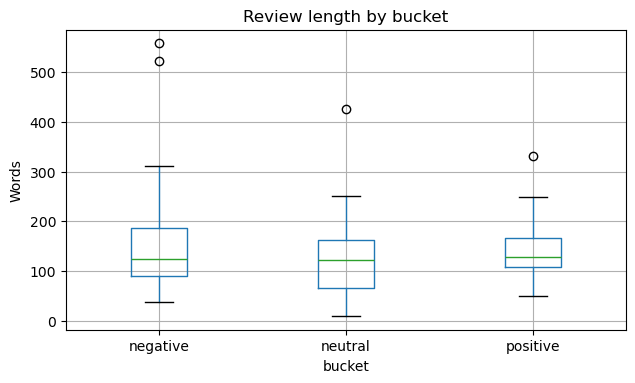

In [4]:
df.boxplot(column="word_count", by="bucket", figsize=(7, 4))
plt.suptitle("")
plt.title("Review length by bucket")
plt.ylabel("Words")
plt.show()

## 4. Baseline: what does random guessing score?

Always predicting the most common class is the bar any real model has to clear.

In [5]:
X = df["review_text"]
y = df["bucket"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dummy = DummyClassifier(strategy="most_frequent")
dummy_scores = cross_val_score(dummy, X, y, cv=cv, scoring="accuracy")
print(f"Dummy baseline accuracy: {dummy_scores.mean():.2f}")

Dummy baseline accuracy: 0.35


## 5. Model: TF-IDF + logistic regression

Everything lives inside one `Pipeline` so the vectorizer is fit on training data only,
inside each cross-validation fold. That avoids data leakage.

In [6]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),   # single words and two-word phrases
        min_df=2,             # ignore terms that appear in only one review
        # stop_words is left off on purpose: words like "not" carry sentiment.
    )),
    ("clf", LogisticRegression(max_iter=1000)),
])

cv_scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
print(f"5-fold CV accuracy: {cv_scores.mean():.2f} (+/- {cv_scores.std():.2f})")
print("Per-fold:", np.round(cv_scores, 2))

5-fold CV accuracy: 0.58 (+/- 0.09)
Per-fold: [0.7  0.45 0.6  0.65 0.5 ]


## 6. Hold-out evaluation


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.56      0.56      0.56         9
     neutral       0.33      0.14      0.20         7
    positive       0.69      1.00      0.82         9

    accuracy                           0.60        25
   macro avg       0.53      0.57      0.52        25
weighted avg       0.54      0.60      0.55        25



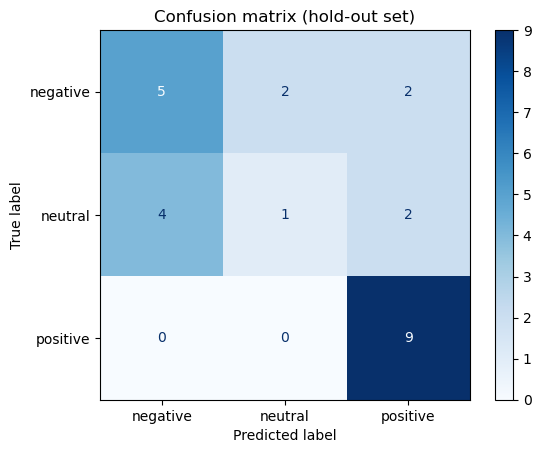

In [8]:
labels = ["negative", "neutral", "positive"]
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=labels, cmap="Blues")
plt.title("Confusion matrix (hold-out set)")
plt.show()

## 7. What did the model learn?


In [9]:
tfidf = model.named_steps["tfidf"]
clf = model.named_steps["clf"]
feature_names = np.array(tfidf.get_feature_names_out())

for i, cls in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[i])[-10:][::-1]
    print(f"{cls.upper():<9}", ", ".join(feature_names[top]))

NEGATIVE  he, was, does, like, on, were, that, to, about, came
NEUTRAL   but it, but, is the, it, there, did, good, wasn, together, not
POSITIVE  film, gotham, the, of, by, films, by the, perfect, batman is, dark


## 8. Where does it go wrong?

In [10]:
errors = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred,
    "review_text": X_test,
})
errors = errors[errors["actual"] != errors["predicted"]]
print(f"{len(errors)} misclassified out of {len(y_test)}\n")

for _, row in errors.iterrows():
    print(f"actual={row['actual']}  predicted={row['predicted']}")
    print(row["review_text"][:300], "\n")

10 misclassified out of 25

actual=neutral  predicted=negative
I agree with most folk that this movie was a treat to the eye. However, I would have liked to see more in the character department, especially the Joker, who is a fascinating character in the comic. In the movie he goes from a murderous psychopath, to a murderous psychopath with a white face. To any 

actual=neutral  predicted=negative
There's something about these older superhero movies that I don't find intriguing for some reason; I feel like the plots are just basic and there's not enough character development. I felt the plot was rushed and there was no context at times, for example when Bruce and Vicki go on a date after just 

actual=negative  predicted=positive
I'm no fan of Burton, a director who has been propped up by A-list designers and DOP's for years...but, I like "Sleepy Hollow", "Big Top Pee Wee" is passable, and "Ed Wood" is a classic (thanks to the brilliant screenplay). I despise "Beetlejunk", though, and 

## 9. Write-up

- **Result:** We reached a CV accuracy of 58% with the folds ranging from 45-70% against our baseline of 35%.
- **Where it struggles:** We see there's a real struggle when it comes to predicting Neutral reviews, most likely because there isn't real neutral language sentiment like positive and negative. Many neutral reviews contain both praise and criticism (“a treat to the eye... however...”). Word-level features pull both ways, and the model caught only 1 of 7 neutral hold-out reviews. As we also see in Section 7, the top words are mostly function words (“he, was, to, of, the”), not sentiment words like “boring”. That means the model is partly fitting noise at this sample size rather than true sentiment language.
- **Limitations:** 100 reviews, along with different lengths of each review. The more there is said, the more sentiment there is to try and recognize and distinct. A three word review of "It was fine" get compared and evaluated next to a 300 word review with much more detail.
- **Next steps:** more user data, compare against a pretrained sentiment model, including stop words, using more uniform reviews.